In [1]:
import torch
import torchvision
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix



In [2]:
transform = transforms.Compose([
    transforms.ToTensor(), 
    transforms.Normalize(0.5, 0.5)])


In [3]:
train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

In [4]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

In [5]:
#Kształt paczki
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)

torch.Size([64, 1, 28, 28]) torch.Size([64])


In [6]:
def build_mlp(hidden_sizes, in_dim=784, out_dim=10):
    layers = [nn.Flatten()]
    prev = in_dim
    for h in hidden_sizes:
        layers.append(nn.Linear(prev, h))
        layers.append(nn.ReLU())
        prev = h
    layers.append(nn.Linear(prev, out_dim))    
    return nn.Sequential(*layers)

In [7]:
model = build_mlp((256, 128))
print(sum(p.numel() for p in model.parameters()))
print(model(xb).shape)

235146
torch.Size([64, 10])


In [8]:
def train_model(model, epochs=10, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct = 0
        for xb,yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
        train_loss = running_loss / len(train_ds)
        train_acc = correct / len(train_ds)
        
        model.eval()
        test_loss_sum = 0.0
        test_correct = 0
        with torch.no_grad():
            for xb, yb in test_loader:
                logits = model(xb)
                loss = criterion(logits, yb)
                test_loss_sum += loss.item() * xb.size(0)
                test_correct += (logits.argmax(dim=1) == yb).sum().item()
        test_loss = test_loss_sum / len(test_ds)
        test_acc = test_correct / len(test_ds)
        
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(epoch, train_loss, test_loss, train_acc, test_acc)
    return history

In [9]:
torch.manual_seed(0)
model = build_mlp((256, 128))
history = train_model(model, epochs=3)

0 0.4973564210255941 0.42664878640174864 0.81815 0.841
1 0.3704723644892375 0.39868177468776705 0.86275 0.8541
2 0.33080643593470255 0.37019415460824967 0.877 0.8657


In [10]:
variants = [(128,), (256, 128), (512, 256, 128)]
results_by_epochs = {}

for n_epochs in (10, 20):
    results = []
    for hs in variants:
        torch.manual_seed(0)
        model = build_mlp(hs)
        params = sum(p.numel() for p in model.parameters())
        history = train_model(model, epochs=n_epochs)
        results.append((hs, params, history["test_acc"][-1], history))
    results_by_epochs[n_epochs] = results

results_10 = results_by_epochs[10]
results_20 = results_by_epochs[20]

0 0.49960660721460975 0.4409080302000046 0.8212666666666667 0.8387
1 0.38034803961118063 0.3969782155036926 0.8608666666666667 0.8579
2 0.3458502014319102 0.3738706764936447 0.8727 0.8659
3 0.3203937927166621 0.3642527107954025 0.8826333333333334 0.8701
4 0.30245456956227623 0.3820936967968941 0.8890166666666667 0.8621
5 0.2884365246772766 0.3557742499470711 0.8940833333333333 0.8705
6 0.27599923125108083 0.3692531974077225 0.8983833333333333 0.8708
7 0.26277649617989857 0.3538869484424591 0.9031166666666667 0.8807
8 0.2534258956273397 0.3531849022388458 0.9069166666666667 0.8781
9 0.24443815970420837 0.3485834646940231 0.90875 0.878
0 0.4973564210255941 0.42664878640174864 0.81815 0.841
1 0.3704723644892375 0.39868177468776705 0.86275 0.8541
2 0.33080643593470255 0.37019415460824967 0.877 0.8657
3 0.3056263244311015 0.35384015398025515 0.8854666666666666 0.874
4 0.28646658357779187 0.34168793532848357 0.8924166666666666 0.8752
5 0.27024516870180765 0.34555691565275193 0.89815 0.8735
6

In [11]:
df = pd.DataFrame({
    "architektura": [str(r[0]) for r in results_20],
    "parametry": [r[1] for r in results_20],
    "acc_10_epok": [r[2] for r in results_10],
    "acc_20_epok": [r[2] for r in results_20],
})
print(df)

      architektura  parametry  acc_10_epok  acc_20_epok
0           (128,)     101770       0.8780       0.8781
1       (256, 128)     235146       0.8860       0.8889
2  (512, 256, 128)     567434       0.8769       0.8915


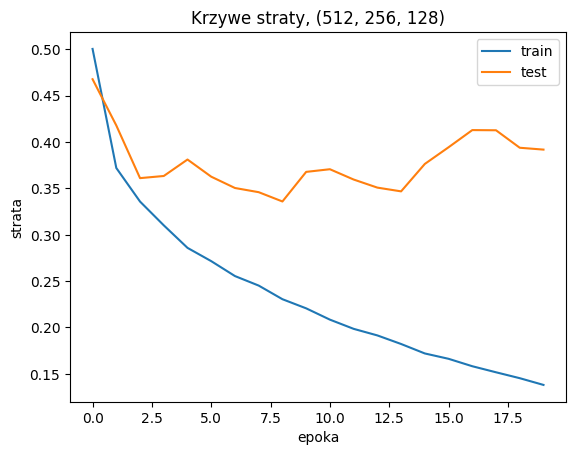

In [12]:
best = max(results_20, key=lambda r: r[2])
hist = best[3]

plt.plot(hist["train_loss"], label="train")
plt.plot(hist["test_loss"], label="test")
plt.xlabel("epoka")
plt.ylabel("strata")
plt.title(f"Krzywe straty, {best[0]}")
plt.legend()
plt.savefig("krzywe.png", dpi=150, bbox_inches="tight")
plt.show()

### Wniosek:
Strata treningowa maleje przez wszystkie 20 epok (z ok. 0,50 do ok. 0,14). Strata testowa ma minimum (ok. 0,34) w okolicy epoki 8 (licząc od 0), a potem rośnie i kończy na ok. 0,39. Rosnąca luka między krzywymi wskazuje na przeuczenie. Accuracy testowe mimo to nie spadło (89,15% po 20 epokach), ponieważ strata mierzy też pewność predykcji, a accuracy tylko to, czy model trafił.

In [13]:
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): ReLU()
  (5): Linear(in_features=256, out_features=128, bias=True)
  (6): ReLU()
  (7): Linear(in_features=128, out_features=10, bias=True)
)


In [14]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        batch_preds = model(x_batch).argmax(dim=1)
        all_preds.append(batch_preds)
        all_labels.append(y_batch)

all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

In [15]:
class_names = train_ds.classes

model.eval()
xb, yb = next(iter(test_loader))
with torch.no_grad():
    preds = model(xb).argmax(dim=1)

wrong = (preds != yb).nonzero().flatten()
right = (preds == yb).nonzero().flatten()
idxs = list(right[:9]) + list(wrong[:9])

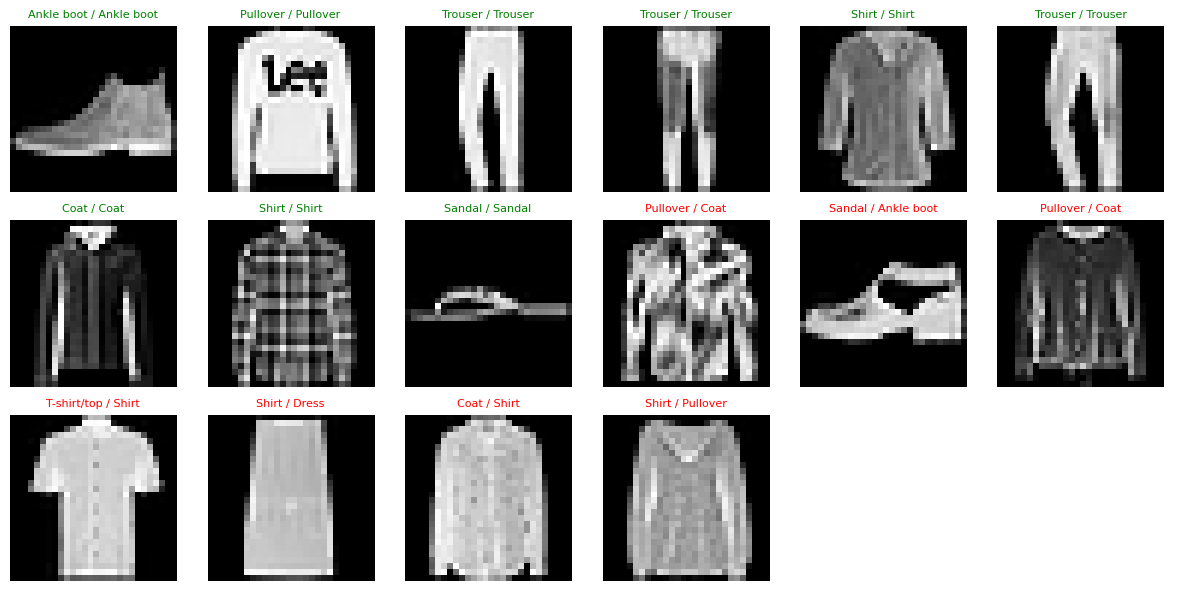

In [16]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, idxs):
    ax.imshow((xb[i] * 0.5 + 0.5).squeeze(), cmap="gray")
    color = "green" if preds[i] == yb[i] else "red"
    ax.set_title(f"{class_names[preds[i]]} / {class_names[yb[i]]}", color=color, fontsize=8)
plt.tight_layout()
plt.savefig("siatka.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
print(all_preds.shape, all_labels.shape)
print((all_preds == all_labels).float().mean())

torch.Size([10000]) torch.Size([10000])
tensor(0.8915)


In [18]:
cm = confusion_matrix(all_labels, all_preds)
print(cm)

[[831   0  20  31   4   0 100   1  13   0]
 [  2 976   0  17   2   0   1   0   2   0]
 [ 21   1 831  19  75   1  46   0   6   0]
 [ 12   3   9 935  25   0  12   0   4   0]
 [  1   0 105  29 826   0  37   0   2   0]
 [  0   0   0   2   0 948   0  33   1  16]
 [112   0  90  33  83   0 671   0  11   0]
 [  0   0   0   0   0  17   0 960   1  22]
 [  4   1   4   3   2   1   3   3 979   0]
 [  1   0   0   0   0   8   0  33   0 958]]


In [19]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
i, j = np.unravel_index(cm_off.argmax(), cm_off.shape)
print(class_names[i], "->", class_names[j], cm_off[i, j])

Shirt -> T-shirt/top 112


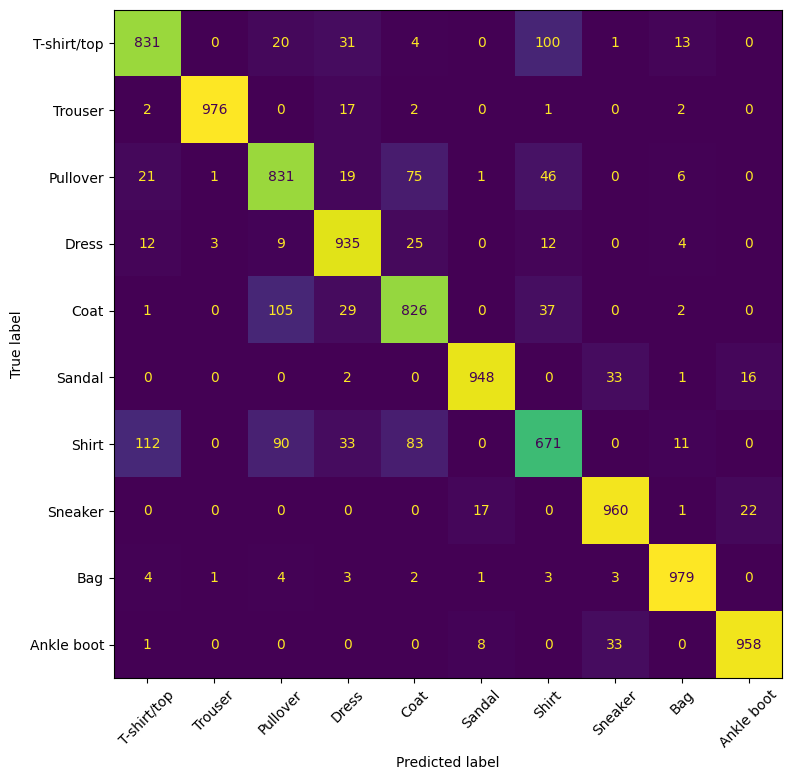

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig("macierz.png", dpi=150, bbox_inches="tight")
plt.show()

### Wniosek z macierzy pomyłek
Najtrudniejszą parą klas jest Shirt i T-shirt/top: 112 koszul zostało sklasyfikowanych jako T-shirt, a 100 T-shirtów jako koszula. Klasa Shirt ma najniższą skuteczność, wynoszącą 67,1%. Kolejną trudną parą jest Pullover i Coat (105 pomyłek Coat z Pullover i 75 w drugą stronę). Są to ubrania górnej części ciała o podobnym kształcie, a MLP po spłaszczeniu obrazu nie wykorzystuje lokalnych wzorców, więc słabo odróżnia drobne szczegóły. Najlepiej rozpoznawane są klasy o wyraźnie odmiennym kształcie, np. Trouser (976/1000), Bag (979/1000) oraz obuwie (Sandal, Sneaker, Ankle boot).